# Exploratory Data Analysis

Data ingestion, missing value audit, temporal patterns, property breakdowns, correlation structure, and empirical lead-time dynamics across 119,390 bookings (July 2015 – August 2017).


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.ticker import MaxNLocator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    roc_curve,
)

pd.set_option("display.float_format", "{:.4f}".format)
np.set_printoptions(suppress=True, precision=4)

In [2]:
# Visualization & Styling


class Theme:
    PRIMARY = "#1f4e79"
    SECONDARY = "#457b9d"
    ACCENT = "#2a9d8f"
    WARNING = "#e76f51"
    DANGER = "#d62828"
    NEUTRAL_DARK = "#2b2d42"
    GRID_COLOR = "#e5e5e5"
    BASELINE_COLOR = "#6c757d"
    DEFAULT_PALETTE = "crest"

    OUTCOME_COLORS = {
        0: "#2a9d8f",  # Check-Out
        1: "#e76f51",  # Canceled
        "Check-Out": "#2a9d8f",
        "Canceled": "#e76f51",
    }


def apply_grid(ax, grid="none"):
    """
    Configures gridlines on a Matplotlib Axes.

    Options:
      - 'none' (default): No gridlines.
      - 'horizontal only': Horizontal gridlines along the y-axis.
      - 'horizontal and vertical': Both horizontal and vertical gridlines.
    """
    if grid == "none":
        ax.grid(False)
    elif grid == "horizontal only":
        ax.grid(
            True,
            axis="y",
            color=Theme.GRID_COLOR,
            linestyle="-",
            linewidth=0.6,
            alpha=0.7,
        )
        ax.grid(False, axis="x")
    elif grid == "horizontal and vertical":
        ax.grid(
            True,
            axis="both",
            color=Theme.GRID_COLOR,
            linestyle="-",
            linewidth=0.6,
            alpha=0.7,
        )
    else:
        raise ValueError(
            f"Unknown grid option: '{grid}'. Use 'none', 'horizontal only', or 'horizontal and vertical'."
        )


def set_style(font_family="sans-serif", grid="none"):
    """
    Sets global Matplotlib styles.
    Gridlines are controlled via `grid` ('none' [default], 'horizontal only', 'horizontal and vertical').
    """
    grid_b = False
    grid_axis = "both"
    if grid == "horizontal only":
        grid_b = True
        grid_axis = "y"
    elif grid == "horizontal and vertical":
        grid_b = True
        grid_axis = "both"
    elif grid == "none":
        grid_b = False
    else:
        raise ValueError(
            f"Unknown grid option: '{grid}'. Use 'none', 'horizontal only', or 'horizontal and vertical'."
        )

    plt.rcParams.update(
        {
            "figure.facecolor": "white",
            "figure.autolayout": False,
            "figure.dpi": 100,
            "axes.facecolor": "white",
            "axes.edgecolor": "#cccccc",
            "axes.linewidth": 0.8,
            "axes.grid": grid_b,
            "axes.grid.axis": grid_axis,
            "grid.color": Theme.GRID_COLOR,
            "grid.linestyle": "-",
            "grid.linewidth": 0.6,
            "grid.alpha": 0.7,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.spines.left": True,
            "axes.spines.bottom": True,
            "axes.titlesize": 12,
            "axes.titleweight": "bold",
            "axes.titlepad": 10,
            "axes.labelsize": 10,
            "axes.labelcolor": Theme.NEUTRAL_DARK,
            "xtick.color": Theme.NEUTRAL_DARK,
            "ytick.color": Theme.NEUTRAL_DARK,
            "xtick.labelsize": 9.5,
            "ytick.labelsize": 9.5,
            "xtick.major.size": 0,
            "ytick.major.size": 0,
            "font.family": font_family,
            "text.color": Theme.NEUTRAL_DARK,
            "legend.frameon": False,
            "legend.fontsize": 9.5,
            "legend.title_fontsize": 10,
        }
    )


def create_figure(
    nrows=1, ncols=1, figsize=None, sharex=False, sharey=False, grid="none"
):
    set_style(grid=grid)
    if figsize is None:
        figsize = (6.5 * ncols, 4.2 * nrows)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=figsize, sharex=sharex, sharey=sharey
    )
    for ax in np.atleast_1d(axes).ravel():
        apply_grid(ax, grid=grid)
    return fig, axes


def add_bar_labels(ax, fmt="percent", padding=3.0, fontsize=9.5, is_horizontal=False):
    for patch in ax.patches:
        h = patch.get_height()
        w = patch.get_width()
        if is_horizontal:
            val = w
            if np.isnan(val) or val == 0:
                continue
            text = (
                f"{val:.1%}"
                if fmt == "percent"
                else (f"{int(val):,}" if fmt == "count" else f"{val:.2f}")
            )
            ax.annotate(
                text,
                (w, patch.get_y() + h / 2.0),
                ha="left",
                va="center",
                fontsize=fontsize,
                xytext=(padding, 0),
                textcoords="offset points",
            )
        else:
            val = h
            if np.isnan(val):
                continue
            text = (
                f"{val:.1%}"
                if fmt == "percent"
                else (f"{int(val):,}" if fmt == "count" else f"{val:.2f}")
            )
            ax.annotate(
                text,
                (patch.get_x() + w / 2.0, h),
                ha="center",
                va="bottom",
                fontsize=fontsize,
                xytext=(0, padding),
                textcoords="offset points",
            )


def plot_cancellation_rate(
    df,
    group_col,
    target_col="is_canceled",
    ax=None,
    title=None,
    top_n=None,
    order=None,
    color=Theme.PRIMARY,
    palette=Theme.DEFAULT_PALETTE,
    show_baseline=True,
    is_horizontal=False,
    xlabel=None,
    ylabel=None,
    grid="none",
):
    if ax is None:
        _, ax = create_figure(grid=grid)
    else:
        apply_grid(ax, grid=grid)

    grouped = (
        df.groupby(group_col, observed=False)[target_col]
        .agg(["mean", "count"])
        .reset_index()
    )
    grouped.columns = [group_col, "rate", "count"]

    if top_n is not None:
        grouped = grouped.sort_values("count", ascending=False).head(top_n)

    if order is not None:
        grouped = (
            grouped.set_index(group_col)
            .reindex(order)
            .reset_index()
            .dropna(subset=["rate"])
        )
    elif is_horizontal:
        grouped = grouped.sort_values("rate", ascending=True)

    bar_kwargs = (
        {"palette": palette, "hue": group_col, "legend": False}
        if palette
        else {"color": color}
    )

    if is_horizontal:
        sns.barplot(data=grouped, y=group_col, x="rate", ax=ax, **bar_kwargs)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
        ax.set_xlim(0, max(grouped["rate"].max() * 1.18, 0.1))
        add_bar_labels(ax, fmt="percent", is_horizontal=True)
        xlabel = xlabel or "Cancellation Rate"
        ylabel = ylabel or ""
    else:
        sns.barplot(data=grouped, x=group_col, y="rate", ax=ax, **bar_kwargs)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
        ax.set_ylim(0, min(max(grouped["rate"].max() * 1.18, 0.1), 1.05))
        add_bar_labels(ax, fmt="percent", is_horizontal=False)
        ylabel = ylabel or "Cancellation Rate"
        xlabel = xlabel or group_col.replace("_", " ").title()

    if show_baseline:
        overall_mean = df[target_col].mean()
        line_func = ax.axvline if is_horizontal else ax.axhline
        line_func(
            overall_mean,
            color=Theme.BASELINE_COLOR,
            linestyle="--",
            linewidth=1.2,
            alpha=0.8,
            label=f"Avg: {overall_mean:.1%}",
        )
        ax.legend(loc="upper right")

    ax.set_title(title or group_col.replace("_", " ").title())
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    return ax


def plot_grid(configs, ncols=2, figsize=None, grid="none"):
    nrows = (len(configs) + ncols - 1) // ncols
    fig, axes = create_figure(nrows=nrows, ncols=ncols, figsize=figsize, grid=grid)
    axes_flat = np.atleast_1d(axes).ravel()

    for idx, cfg in enumerate(configs):
        ax = axes_flat[idx]
        func = cfg["func"]
        kwargs = cfg.get("args", {}).copy()
        kwargs["ax"] = ax
        func(**kwargs)
        apply_grid(ax, grid=grid)

    for idx in range(len(configs), len(axes_flat)):
        axes_flat[idx].set_visible(False)

    plt.tight_layout()
    return fig, axes


set_style(grid="none")

In [3]:
df = pd.read_csv("data/hotel_bookings.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0000,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0000,NaN,0,Transient,98.0000,0,1,Check-Out,2015-07-03


In [4]:
# Missing values audit across all columns
missing_counts = df.isnull().sum()
missing_cols = missing_counts[missing_counts > 0]
missing_df = pd.DataFrame(
    {
        "Missing Count": missing_cols,
        "Percentage": (missing_cols / len(df) * 100).map("{:.2f}%".format),
        "Dtype": df[missing_cols.index].dtypes,
    }
).sort_values("Missing Count", ascending=False)

print(f"Total missing values: {missing_counts.sum():,}")
print(f"Columns with missing values ({len(missing_cols)} of {len(df.columns)}):\n")
print(missing_df.to_string())

# Impute missing values for retained pre-booking features
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")

# Encode structural missingness for agent and company as binary indicators
df["has_agent"] = df["agent"].notnull().astype(int)
df["has_company"] = df["company"].notnull().astype(int)

print("\nMissing value handling:")
print("  - 'children': Imputed 4 missing values with 0 (mode / median)")
print("  - 'country':  Imputed 488 missing values with 'Unknown' (distinct categorical level)")
print("  - 'agent':    Excluded raw ID; engineered binary flag 'has_agent' (24.7% vs 39.0% cancel rate)")
print("  - 'company':  Excluded raw ID; engineered binary flag 'has_company' (17.5% vs 38.2% cancel rate)")


Total missing values: 129,425
Columns with missing values (4 of 32):

          Missing Count Percentage    Dtype
company          112593     94.31%  float64
agent             16340     13.69%  float64
country             488      0.41%      str
children              4      0.00%  float64

Missing value handling:
  - 'children': Imputed 4 missing values with 0 (mode / median)
  - 'country':  Imputed 488 missing values with 'Unknown' (distinct categorical level)
  - 'agent':    Excluded raw ID; engineered binary flag 'has_agent' (24.7% vs 39.0% cancel rate)
  - 'company':  Excluded raw ID; engineered binary flag 'has_company' (17.5% vs 38.2% cancel rate)


In [5]:
# Parse arrival date
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str)
    + "-"
    + df["arrival_date_month"].astype(str)
    + "-"
    + df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
)

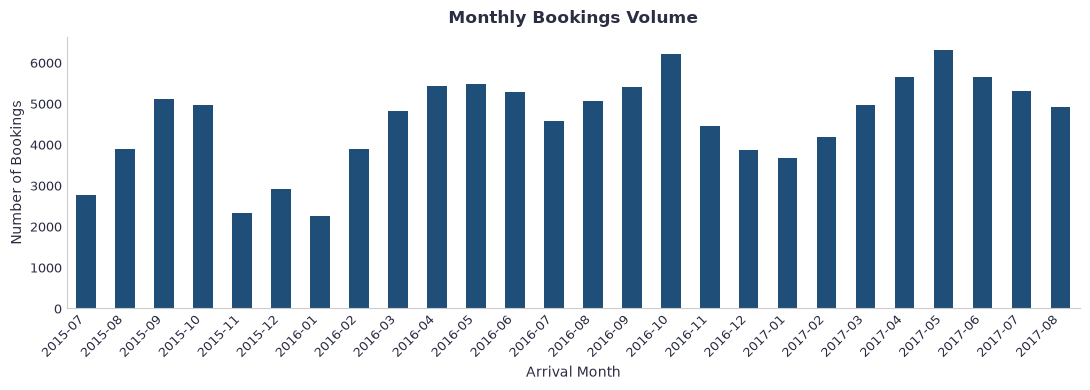

In [6]:
# Monthly booking volume
counts = df.set_index("arrival_date").resample("MS").size()
counts.index = counts.index.strftime("%Y-%m")

fig, ax = create_figure(figsize=(11, 4))
counts.plot(kind="bar", ax=ax, color=Theme.PRIMARY)
ax.set_title("Monthly Bookings Volume")
ax.set_xlabel("Arrival Month")
ax.set_ylabel("Number of Bookings")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


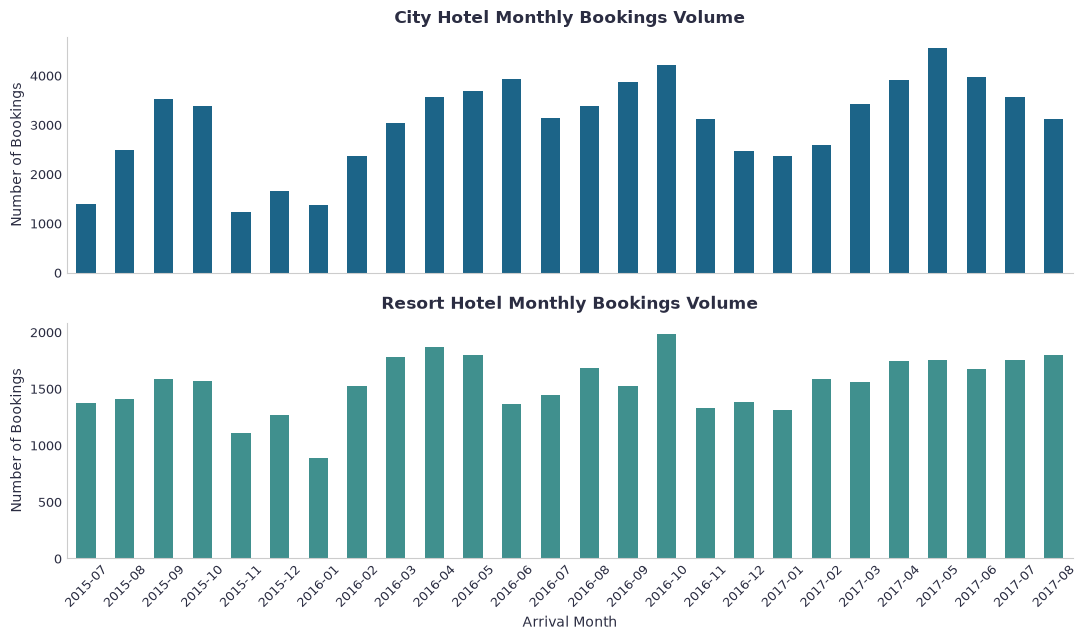

In [7]:
# Monthly booking volume by hotel
monthly_city = (
    df[df["hotel"] == "City Hotel"]
    .set_index("arrival_date")
    .resample("MS")
    .size()
)
monthly_city.index = monthly_city.index.strftime("%Y-%m")

monthly_resort = (
    df[df["hotel"] == "Resort Hotel"]
    .set_index("arrival_date")
    .resample("MS")
    .size()
)
monthly_resort.index = monthly_resort.index.strftime("%Y-%m")

crest = sns.color_palette("crest", 6)
c_city = crest[4]
c_resort = crest[2]

fig, axes = create_figure(nrows=2, ncols=1, figsize=(11, 6.5), sharex=True)

monthly_city.plot(kind="bar", ax=axes[0], color=c_city)
axes[0].set_title("City Hotel Monthly Bookings Volume")
axes[0].set_ylabel("Number of Bookings")

monthly_resort.plot(kind="bar", ax=axes[1], color=c_resort)
axes[1].set_title("Resort Hotel Monthly Bookings Volume")
axes[1].set_xlabel("Arrival Month")
axes[1].set_ylabel("Number of Bookings")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


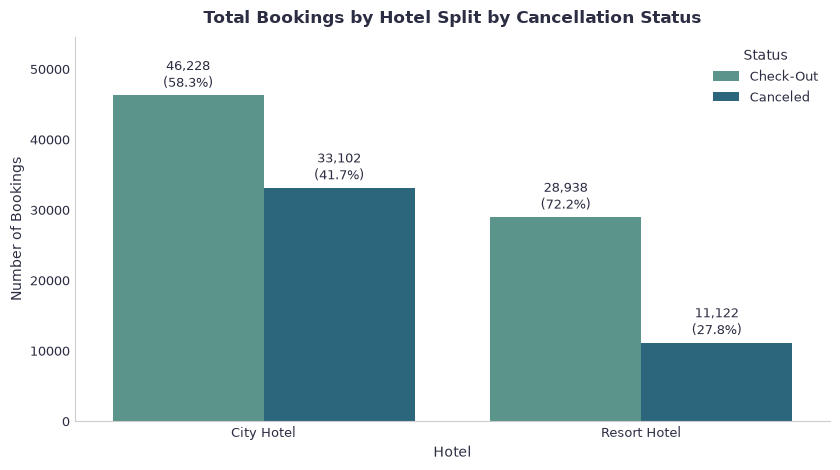

In [8]:
# Total bookings by hotel split into canceled and non-canceled bookings
hotel_df = df.groupby(["hotel", "is_canceled"]).size().reset_index(name="count")
hotel_df["Status"] = hotel_df["is_canceled"].map({0: "Check-Out", 1: "Canceled"})
totals = df.groupby("hotel").size().to_dict()

fig, ax = create_figure(figsize=(8.5, 4.8))
sns.barplot(
    data=hotel_df,
    x="hotel",
    y="count",
    hue="Status",
    palette="crest",
    ax=ax,
)
ax.set_title("Total Bookings by Hotel Split by Cancellation Status")
ax.set_xlabel("Hotel")
ax.set_ylabel("Number of Bookings")
ax.set_ylim(0, max(hotel_df["count"]) * 1.18)

hotels = [label.get_text() for label in ax.get_xticklabels()]
for container in ax.containers:
    for idx, bar in enumerate(container):
        h = bar.get_height()
        if h > 0:
            hotel = hotels[idx]
            pct = h / totals[hotel]
            ax.annotate(
                f"{int(h):,}\n({pct:.1%})",
                (bar.get_x() + bar.get_width() / 2.0, h),
                ha="center",
                va="bottom",
                fontsize=9.5,
                xytext=(0, 3),
                textcoords="offset points",
            )

ax.legend(title="Status", loc="upper right")
plt.tight_layout()
plt.show()


### Temporal Volume & Property Distribution

- **Observation Window:** 26 continuous months (July 2015 – August 2017).
- **Volume & Seasonal Dynamics:**
  - **Property Preponderance:** City Hotel accounts for the clear majority of bookings in every single month (61%–72% monthly share). Even during July–August, City Hotel represents 64.3% of reservations (17,071 City vs 9,467 Resort).
  - **Combined Series:** Heavily driven by City Hotel volume, yielding bimodal peaks in spring (April–May) and autumn (September–October), reaching highs in October 2016 (6,203) and May 2017 (6,313), with troughs in winter (November–January, dipping to 2,248 in January 2016).
  - **Property Trends:** City Hotel sustains elevated booking volumes from March through October (peaking at 8,983 in August). Resort Hotel volume is lower and flatter year-round, seeing its own internal seasonal uptick in July–August (4,573 and 4,894).
- **City Hotel:** 79,330 bookings (66.4% of total); 41.7% cancellation rate (33,102 canceled).
- **Resort Hotel:** 40,060 bookings (33.6% of total); 27.8% cancellation rate (11,122 canceled).
- **Aggregate Rate:** 37.04% overall cancellation rate across the dataset (44,224 of 119,390).


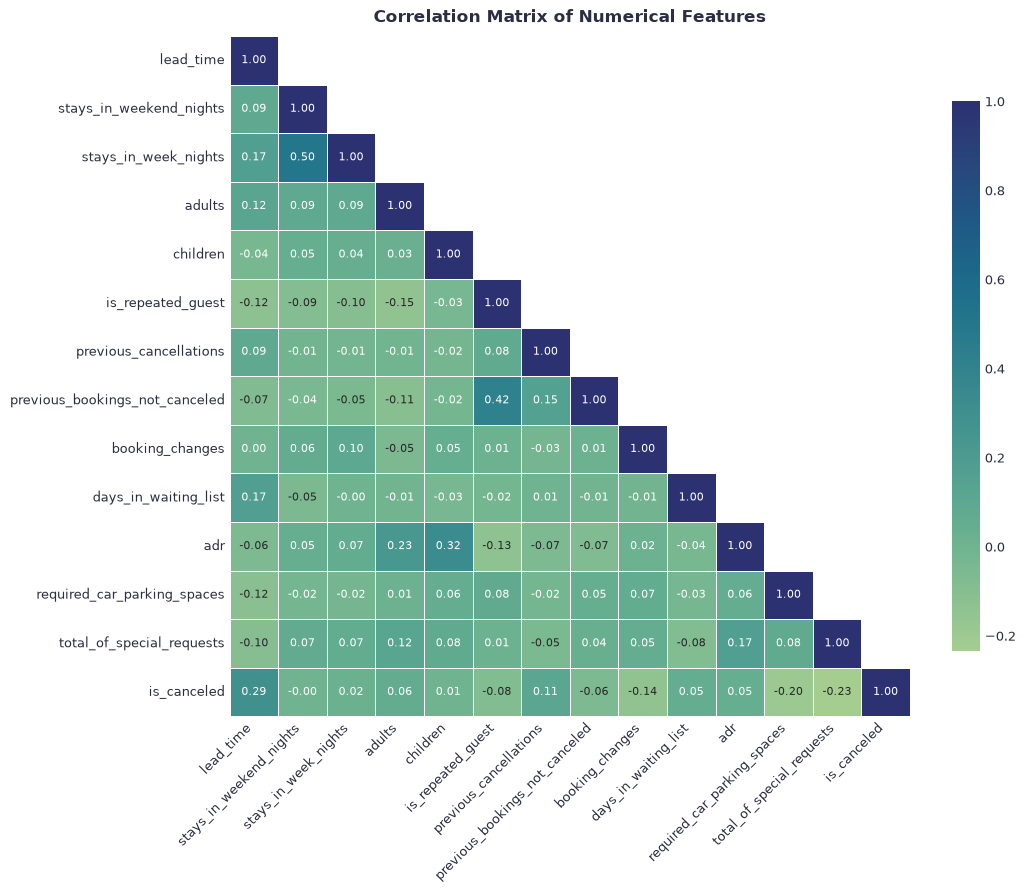

In [9]:
# Correlation matrix across numerical features
num_cols = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "is_canceled",
]
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = create_figure(figsize=(11, 9))
sns.heatmap(
    corr,
    mask=mask,
    cmap="crest",
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax,
    annot_kws={"size": 8},
)
ax.set_title("Correlation Matrix of Numerical Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Correlation Matrix Insights

- **Strongest Positive Associations:** `lead_time` exhibits the highest linear correlation with cancellation ($r = +0.293$), followed by `previous_cancellations` ($r = +0.110$).
- **Strongest Negative Associations:** `total_of_special_requests` ($r = -0.235$), `required_car_parking_spaces` ($r = -0.196$), and `booking_changes` ($r = -0.144$) exhibit the strongest negative associations (the latter two audited as post-booking leaks below).
- **Negligible Target Correlations:** Stay length (`stays_in_weekend_nights` $r = -0.002$, `stays_in_week_nights` $r = +0.025$) and party size (`children` $r = +0.005$, `adults` $r = +0.060$) have negligible linear association with cancellation.
- **Inter-Feature Collinearity:** No feature pairs exceed $|r| = 0.50$, indicating low multicollinearity among numeric features. Highest pairs are structural: weekend vs week nights ($r = +0.499$), repeat guest status vs previous completed bookings ($r = +0.418$), and children vs ADR ($r = +0.325$).


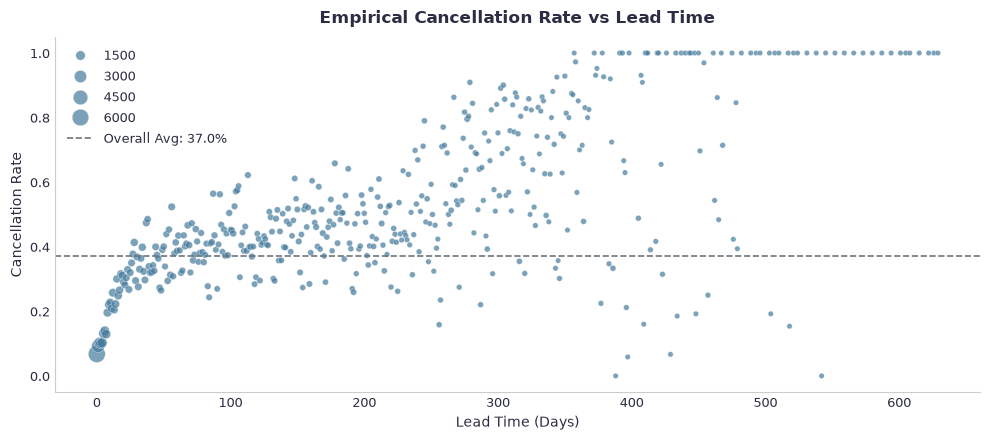

In [10]:
# Empirical cancellation rate by lead time
lead_canc = df.groupby("lead_time")["is_canceled"].agg(["mean", "count"]).reset_index()
lead_canc = lead_canc[lead_canc["count"] >= 10]

fig, ax = create_figure(figsize=(10, 4.5))
sns.scatterplot(
    data=lead_canc,
    x="lead_time",
    y="mean",
    size="count",
    sizes=(15, 150),
    color=Theme.SECONDARY,
    alpha=0.7,
    ax=ax,
    legend="brief",
)
ax.set_title("Empirical Cancellation Rate vs Lead Time")
ax.set_xlabel("Lead Time (Days)")
ax.set_ylabel("Cancellation Rate")
ax.axhline(
    df["is_canceled"].mean(),
    color=Theme.BASELINE_COLOR,
    linestyle="--",
    linewidth=1.2,
    label=f"Overall Avg: {df['is_canceled'].mean():.1%}",
)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Lead Time Dynamics

- **Monotonic Cancellation Gradient:** Cancellation rate scales directly with booking advance window: <15% for bookings made within 14 days, rising to >45% for bookings >180 days.
- **Booking Concentration:** The vast majority of completed check-outs occur at low lead times (<30 days), whereas reservations made far in advance carry disproportionately high cancellation rates.


---
# Feature Selection & Leakage Audit

**Prediction Point:** Booking creation. Exclude anything determined afterward.

**Exclusion Criteria:**
- **Target Leaks:** Directly encodes outcome (`reservation_status`, `reservation_status_date`).
- **Operational / Check-in Leaks:** Recorded after creation or stamped retroactively (`deposit_type`, `required_car_parking_spaces`, `assigned_room_type`, `booking_changes`).
- **Sparsity / Redundancy:** `company` (94.3% null), `agent` (high-cardinality ID), redundant date fragments.


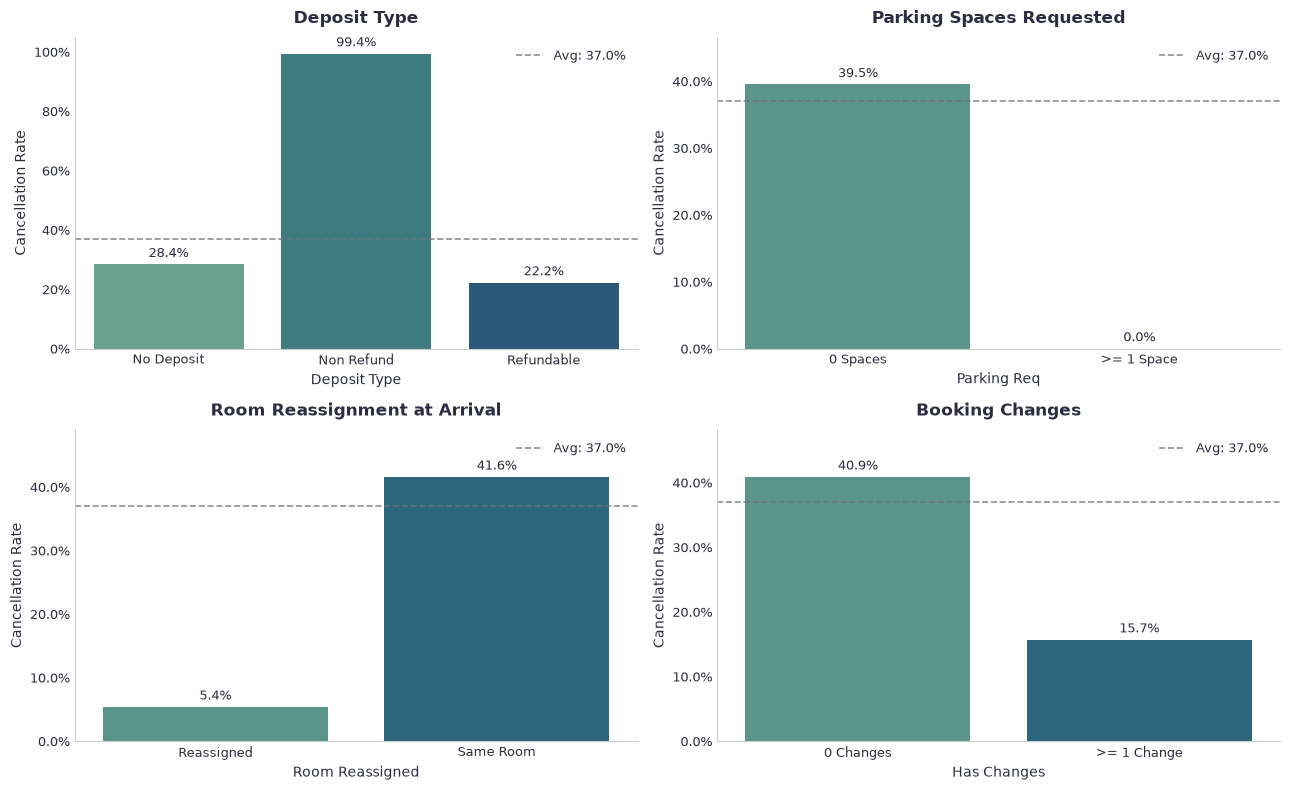

In [11]:
# Visualizing Operational Leaks & Anomalies

df["parking_req"] = (df["required_car_parking_spaces"] > 0).map(
    {False: "0 Spaces", True: ">= 1 Space"}
)
df["room_reassigned"] = (df["assigned_room_type"] != df["reserved_room_type"]).map(
    {False: "Same Room", True: "Reassigned"}
)
df["has_changes"] = (df["booking_changes"] > 0).map(
    {False: "0 Changes", True: ">= 1 Change"}
)

leak_configs = [
    {
        "func": plot_cancellation_rate,
        "args": {
            "df": df,
            "group_col": "deposit_type",
            "title": "Deposit Type",
            "palette": "crest",
        },
    },
    {
        "func": plot_cancellation_rate,
        "args": {
            "df": df,
            "group_col": "parking_req",
            "title": "Parking Spaces Requested",
            "palette": "crest",
        },
    },
    {
        "func": plot_cancellation_rate,
        "args": {
            "df": df,
            "group_col": "room_reassigned",
            "title": "Room Reassignment at Arrival",
            "palette": "crest",
        },
    },
    {
        "func": plot_cancellation_rate,
        "args": {
            "df": df,
            "group_col": "has_changes",
            "title": "Booking Changes",
            "palette": "crest",
        },
    },
]
fig, axes = plot_grid(leak_configs, ncols=2, figsize=(13, 8))
plt.show()

### Excluded Variables: Key Findings

- **`deposit_type`:** 99.36% of `Non Refund` cancel (14,494 of 14,587; 99.95% in test). Counter-intuitive; reflects system retroactively tagging forfeited deposits upon cancellation.
- **`required_car_parking_spaces`:** 0 of 7,416 cancel (100% check-in). Parking is assigned upon physical arrival.
- **`assigned_room_type`:** 18.8% reassignments for check-outs vs 1.8% for cancellations. Room assignment occurs at check-in.
- **`booking_changes`:** Occurs between booking and departure (mean: 0.29 check-out vs 0.10 canceled).
- **`company` / `agent`:** `company` is 94.3% missing; `agent` is sparse/high-cardinality.


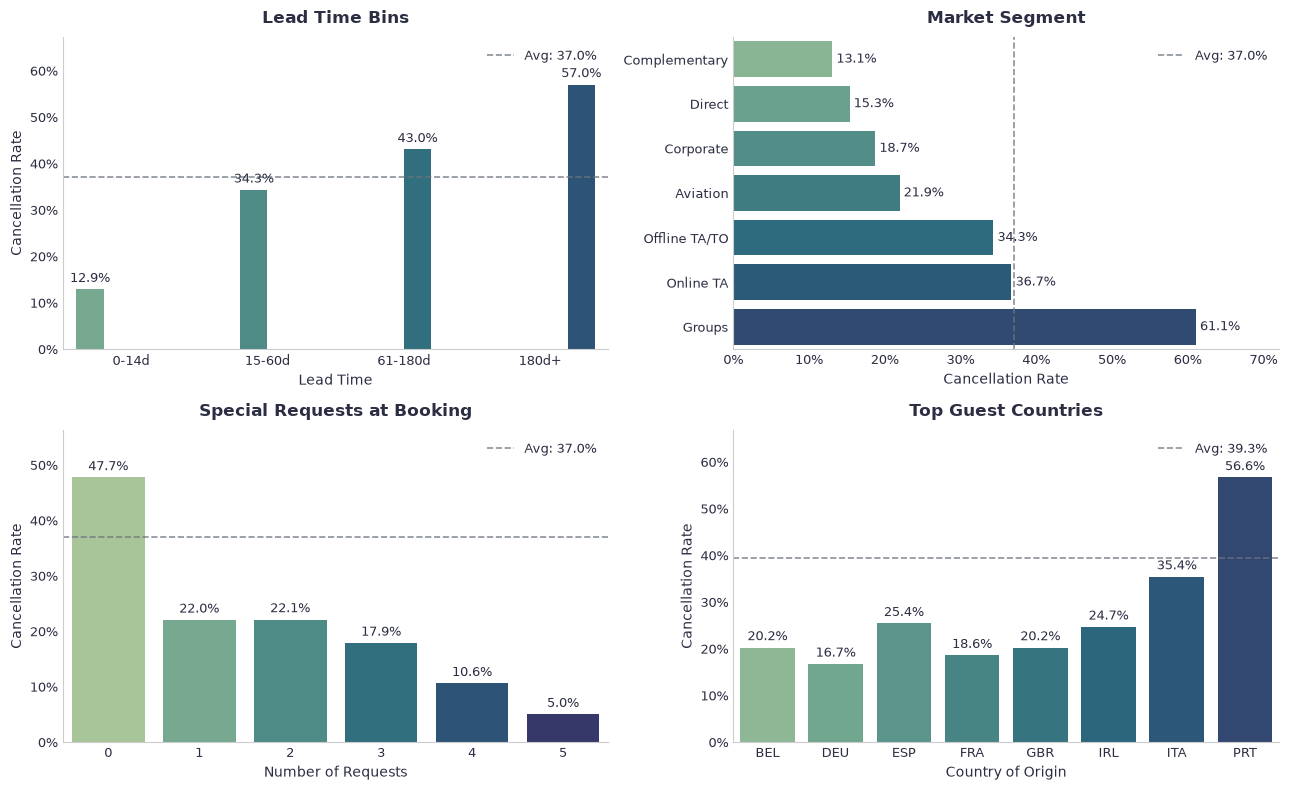

In [12]:
# Visualizing Pre-Booking Signals
df["lead_time_bin"] = pd.cut(
    df["lead_time"],
    bins=[-1, 14, 60, 180, 800],
    labels=["0-14d", "15-60d", "61-180d", "180d+"],
)
clean_segments = df[df["market_segment"] != "Undefined"]
top_countries = df[df["country"].isin(df["country"].value_counts().head(8).index)]

signal_configs = [
    {
        "func": plot_cancellation_rate,
        "args": {
            "df": df,
            "group_col": "lead_time_bin",
            "title": "Lead Time Bins",
            "palette": "crest",
            "xlabel": "Lead Time",
        },
    },
    {
        "func": plot_cancellation_rate,
        "args": {
            "df": clean_segments,
            "group_col": "market_segment",
            "title": "Market Segment",
            "palette": "crest",
            "is_horizontal": True,
        },
    },
    {
        "func": plot_cancellation_rate,
        "args": {
            "df": df,
            "group_col": "total_of_special_requests",
            "title": "Special Requests at Booking",
            "palette": "crest",
            "xlabel": "Number of Requests",
        },
    },
    {
        "func": plot_cancellation_rate,
        "args": {
            "df": top_countries,
            "group_col": "country",
            "title": "Top Guest Countries",
            "palette": "crest",
            "xlabel": "Country of Origin",
        },
    },
]
fig, axes = plot_grid(signal_configs, ncols=2, figsize=(13, 8))
plt.show()

### Retained Pre-Booking Features (23)

| Category | Variables |
| :--- | :--- |
| **Timing** | `lead_time`, `arrival_date_month`, `arrival_date_week_number`, `days_in_waiting_list` |
| **Stay** | `hotel`, `stays_in_weekend_nights`, `stays_in_week_nights`, `reserved_room_type`, `meal` |
| **Party** | `adults`, `children`, `babies`, `country` |
| **Channel** | `market_segment`, `distribution_channel`, `customer_type`, `has_agent`, `has_company` |
| **History** | `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` |
| **Other** | `adr`, `total_of_special_requests` |


In [13]:
# Define feature selection and create leak-free dataset
DROP_LEAKS_AND_ADMIN = [
    "reservation_status",  # Direct outcome leak
    "reservation_status_date",  # Direct outcome leak
    "assigned_room_type",  # Check-in leak (assigned at arrival)
    "booking_changes",  # Post-creation accumulated modifications
    "required_car_parking_spaces",  # Check-in leak (0% cancellation, allocated at gate)
    "deposit_type",  # Retroactive penalty / default block flag
    "agent",  # High-cardinality administrative ID
    "company",  # 94.3% missing
    "arrival_date_year",  # Redundant with arrival_date / month
    "arrival_date_day_of_month",  # Redundant with week number / month
]

TARGET = "is_canceled"

SELECTED_FEATURES = [
    "hotel",
    "lead_time",
    "arrival_date_month",
    "arrival_date_week_number",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "reserved_room_type",
    "days_in_waiting_list",
    "customer_type",
    "adr",
    "total_of_special_requests",
    "has_agent",
    "has_company",
]

print(f"Original shape: {df.shape}")
print(f"Clean feature matrix shape: ({len(df)}, {len(SELECTED_FEATURES)})")
print(f"Missing values in clean feature set: {df[SELECTED_FEATURES].isnull().sum().sum()} (0 nulls)")
print(f"\nSelected Features ({len(SELECTED_FEATURES)}):\n ", SELECTED_FEATURES)
print(
    f"\nDropped Leaky / Redundant Features ({len(DROP_LEAKS_AND_ADMIN)}):\n ",
    DROP_LEAKS_AND_ADMIN,
)


Original shape: (119390, 39)
Clean feature matrix shape: (119390, 23)
Missing values in clean feature set: 0 (0 nulls)

Selected Features (23):
  ['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'days_in_waiting_list', 'customer_type', 'adr', 'total_of_special_requests', 'has_agent', 'has_company']

Dropped Leaky / Redundant Features (10):
  ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'required_car_parking_spaces', 'deposit_type', 'agent', 'company', 'arrival_date_year', 'arrival_date_day_of_month']


---
# Time-Based Train / Validation / Test Split

We use a time-based split, not a random split, so the test reflects predicting future bookings. Each month is kept intact across both locations, and results will be reported for each hotel separately as well as combined.

| Split | Months | Date Range | Bookings | Overall Cancel % | City Hotel Cancel % | Resort Hotel Cancel % |
| :--- | :--- | :--- | :---: | :---: | :---: | :---: |
| **Train** | M1–18 | 2015-07 to 2016-12 | 78,703 | 36.19% | 41.32% | 26.29% |
| **Validation** | M19–22 | 2017-01 to 2017-04 | 18,489 | 36.48% | 42.44% | 24.63% |
| **Test** | M23–26 | 2017-05 to 2017-08 | 22,198 | 40.55% | 42.55% | 36.20% |


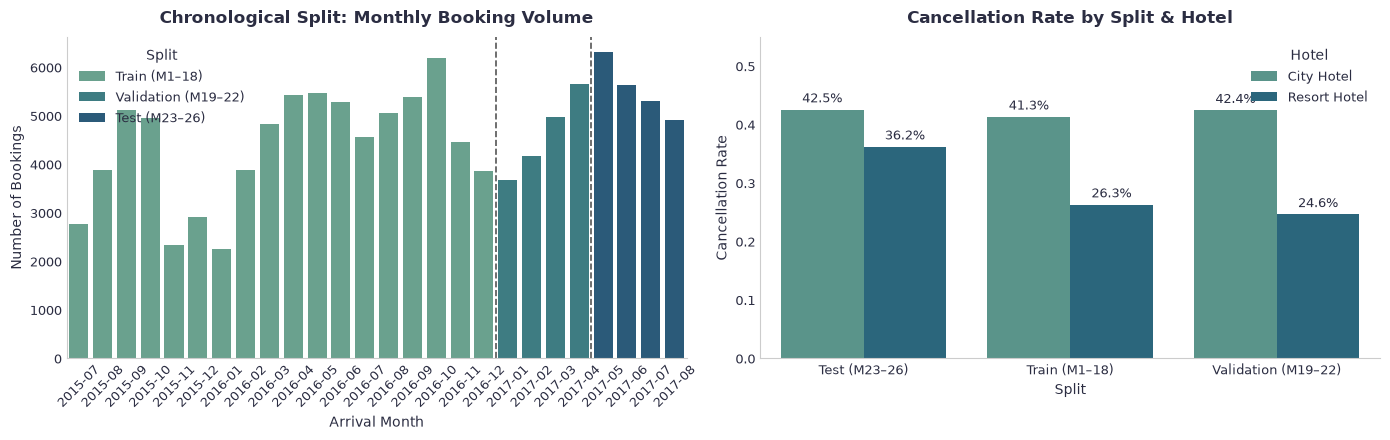

In [14]:
# Visualizing the chronological train/val/test split and cancellation rates
month_periods = df["arrival_date"].dt.to_period("M")
unique_months = sorted(month_periods.unique())
month_map = {m: i + 1 for i, m in enumerate(unique_months)}
df["month_idx"] = month_periods.map(month_map)

df["split"] = "Train (M1–18)"
df.loc[(df["month_idx"] > 18) & (df["month_idx"] <= 22), "split"] = (
    "Validation (M19–22)"
)
df.loc[df["month_idx"] > 22, "split"] = "Test (M23–26)"

monthly_df = (
    df.set_index("arrival_date").resample("MS").size().reset_index(name="count")
)
monthly_df["month_str"] = monthly_df["arrival_date"].dt.strftime("%Y-%m")
monthly_df["month_idx"] = range(1, len(monthly_df) + 1)
monthly_df["split"] = "Train (M1–18)"
monthly_df.loc[
    (monthly_df["month_idx"] > 18) & (monthly_df["month_idx"] <= 22), "split"
] = "Validation (M19–22)"
monthly_df.loc[monthly_df["month_idx"] > 22, "split"] = "Test (M23–26)"

fig, axes = create_figure(nrows=1, ncols=2, figsize=(14, 4.5), grid="none")

# Monthly booking volume colored by split
sns.barplot(
    data=monthly_df,
    x="month_str",
    y="count",
    hue="split",
    palette="crest",
    ax=axes[0],
    dodge=False,
)
axes[0].set_title("Chronological Split: Monthly Booking Volume")
axes[0].set_xlabel("Arrival Month")
axes[0].set_ylabel("Number of Bookings")
axes[0].axvline(17.5, color="#555555", linestyle="--", linewidth=1.2)
axes[0].axvline(21.5, color="#555555", linestyle="--", linewidth=1.2)
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="Split", loc="upper left")

# Cancellation rates across splits by hotel
split_rates = df.groupby(["split", "hotel"])["is_canceled"].mean().reset_index()
sns.barplot(
    data=split_rates,
    x="split",
    y="is_canceled",
    hue="hotel",
    palette="crest",
    ax=axes[1],
)
axes[1].set_title("Cancellation Rate by Split & Hotel")
axes[1].set_xlabel("Split")
axes[1].set_ylabel("Cancellation Rate")
axes[1].set_ylim(0, 0.55)
for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(
            f"{h:.1%}",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="bottom",
            fontsize=9.5,
            xytext=(0, 3),
            textcoords="offset points",
        )
axes[1].legend(title="Hotel", loc="upper right")

plt.tight_layout()
plt.show()


In [15]:
# Construct chronological train, validation, and test matrices
train_mask = df["split"] == "Train (M1–18)"
val_mask = df["split"] == "Validation (M19–22)"
test_mask = df["split"] == "Test (M23–26)"

# Feature matrices using the clean 23-feature set
X_train, y_train = df.loc[train_mask, SELECTED_FEATURES], df.loc[train_mask, TARGET]
X_val, y_val = df.loc[val_mask, SELECTED_FEATURES], df.loc[val_mask, TARGET]
X_test, y_test = df.loc[test_mask, SELECTED_FEATURES], df.loc[test_mask, TARGET]

# Retain hotel tracking for per-hotel evaluation
hotel_train = df.loc[train_mask, "hotel"].values
hotel_val = df.loc[val_mask, "hotel"].values
hotel_test = df.loc[test_mask, "hotel"].values

print("Split Partitions (Clean 23 Features):")
print(
    f"  Train (M1–18):       {len(X_train):,d} rows  |  Cancel Rate: {y_train.mean():.2%}  (City: {df.loc[train_mask & (df['hotel'] == 'City Hotel'), TARGET].mean():.2%}, Resort: {df.loc[train_mask & (df['hotel'] == 'Resort Hotel'), TARGET].mean():.2%})"
)
print(
    f"  Validation (M19–22): {len(X_val):,d} rows  |  Cancel Rate: {y_val.mean():.2%}  (City: {df.loc[val_mask & (df['hotel'] == 'City Hotel'), TARGET].mean():.2%}, Resort: {df.loc[val_mask & (df['hotel'] == 'Resort Hotel'), TARGET].mean():.2%})"
)
print(
    f"  Test (M23–26):       {len(X_test):,d} rows  |  Cancel Rate: {y_test.mean():.2%}  (City: {df.loc[test_mask & (df['hotel'] == 'City Hotel'), TARGET].mean():.2%}, Resort: {df.loc[test_mask & (df['hotel'] == 'Resort Hotel'), TARGET].mean():.2%})"
)
print("\nPartition Shapes:")
print(f"  X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"  X_val:   {X_val.shape}, y_val:   {y_val.shape}")
print(f"  X_test:  {X_test.shape}, y_test:  {y_test.shape}")


Split Partitions (Clean 23 Features):
  Train (M1–18):       78,703 rows  |  Cancel Rate: 36.19%  (City: 41.32%, Resort: 26.29%)
  Validation (M19–22): 18,489 rows  |  Cancel Rate: 36.48%  (City: 42.44%, Resort: 24.63%)
  Test (M23–26):       22,198 rows  |  Cancel Rate: 40.55%  (City: 42.55%, Resort: 36.20%)

Partition Shapes:
  X_train: (78703, 23), y_train: (78703,)
  X_val:   (18489, 23), y_val:   (18489,)
  X_test:  (22198, 23), y_test:  (22198,)


---
# Models

Evaluation of constant cancellation rate baselines (training mean and test mean) and a univariate logistic regression model on chronological train, validation, and test partitions.


Constant Training Baseline Rate: 36.1854%
Constant Test Baseline Rate:     40.5487%
Fitted Slope: 0.006723
Fitted Intercept: -1.284565
Decision Boundary (P = 0.5): 191.1 days


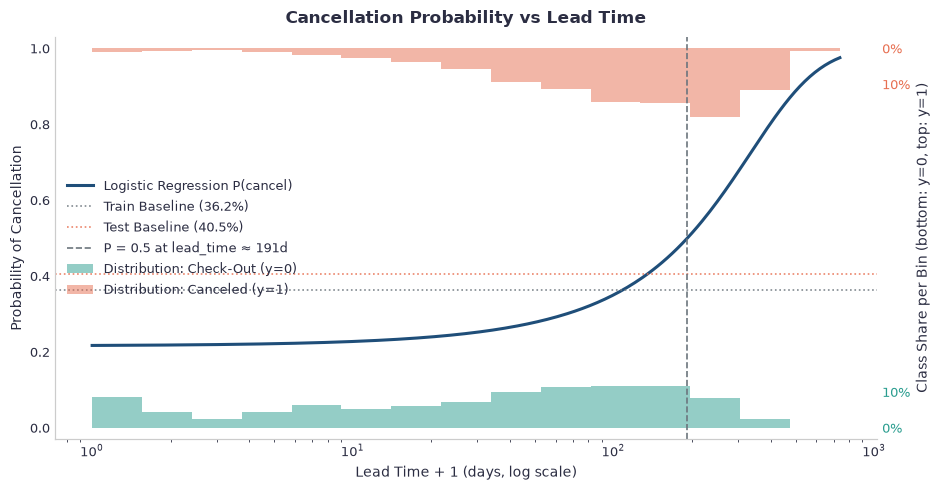

In [16]:
# Constant Baselines & Univariate Logistic Regression Models

# Constant Cancellation Rate Baseline (Training Mean)
p_train_const = y_train.mean()
print(f"Constant Training Baseline Rate: {p_train_const:.4%}")

# Constant Test Mean Baseline (Test Target Mean)
p_test_const = y_test.mean()
print(f"Constant Test Baseline Rate:     {p_test_const:.4%}")

# Univariate Logistic Regression on lead_time
logit_model = LogisticRegression()
logit_model.fit(X_train[["lead_time"]], y_train)

slope = logit_model.coef_[0, 0]
intercept = logit_model.intercept_[0]
boundary = -intercept / slope
print(f"Fitted Slope: {slope:.6f}")
print(f"Fitted Intercept: {intercept:.6f}")
print(f"Decision Boundary (P = 0.5): {boundary:.1f} days")

# Visualize Fitted Probability Curve and Training Class Distributions
x_train_vals = X_train["lead_time"].values + 1
y_train_vals = y_train.values

x_line_plot = np.geomspace(x_train_vals.min(), x_train_vals.max(), 300)
x_line_model = (x_line_plot - 1).reshape(-1, 1)
p_line = logit_model.predict_proba(pd.DataFrame(x_line_model, columns=["lead_time"]))[:, 1]

bins = np.geomspace(x_train_vals.min(), x_train_vals.max(), 16)
counts_0, edges = np.histogram(x_train_vals[y_train_vals == 0], bins=bins)
counts_1, _ = np.histogram(x_train_vals[y_train_vals == 1], bins=bins)
widths = np.diff(edges)

props_0 = counts_0 / max(counts_0.sum(), 1)
props_1 = counts_1 / max(counts_1.sum(), 1)
band = 0.18
scale = band / max(props_0.max(), props_1.max(), 1e-12)

fig, ax = create_figure(figsize=(9.5, 5), grid="none")
ax.bar(
    edges[:-1],
    props_0 * scale,
    width=widths,
    align="edge",
    color=Theme.OUTCOME_COLORS[0],
    alpha=0.5,
    label="Distribution: Check-Out (y=0)",
)
ax.bar(
    edges[:-1],
    -props_1 * scale,
    width=widths,
    align="edge",
    bottom=1,
    color=Theme.OUTCOME_COLORS[1],
    alpha=0.5,
    label="Distribution: Canceled (y=1)",
)
ax.plot(
    x_line_plot,
    p_line,
    color=Theme.PRIMARY,
    linewidth=2.2,
    label="Logistic Regression P(cancel)",
)
ax.axhline(
    p_train_const,
    color=Theme.BASELINE_COLOR,
    linestyle=":",
    linewidth=1.2,
    alpha=0.85,
    label=f"Train Baseline ({p_train_const:.1%})",
)
ax.axhline(
    p_test_const,
    color="#e76f51",
    linestyle=":",
    linewidth=1.2,
    alpha=0.85,
    label=f"Test Baseline ({p_test_const:.1%})",
)

if slope != 0 and x_train_vals.min() < boundary + 1 < x_train_vals.max():
    ax.axvline(
        boundary + 1,
        color=Theme.BASELINE_COLOR,
        linestyle="--",
        linewidth=1.2,
        label=f"P = 0.5 at lead_time ≈ {boundary:.0f}d",
    )

ax.set_xscale("log")
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("Lead Time + 1 (days, log scale)")
ax.set_ylabel("Probability of Cancellation")
ax.set_title("Cancellation Probability vs Lead Time")

max_prop = max(props_0.max(), props_1.max(), 1e-12)
prop_ticks = MaxNLocator(nbins=3, steps=[1, 2, 5, 10]).tick_values(0, max_prop)
prop_ticks = prop_ticks[(prop_ticks >= 0) & (prop_ticks <= max_prop * 1.001)]

bottom_pos = prop_ticks * scale
top_pos = 1 - prop_ticks * scale
tick_pos = np.concatenate([bottom_pos, top_pos])
tick_labels = [f"{p * 100:g}%" for p in prop_ticks] * 2

ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
ax2.set_yticks(tick_pos)
ax2.set_yticklabels(tick_labels)
ax2.set_ylabel("Class Share per Bin (bottom: y=0, top: y=1)")
for label, pos in zip(ax2.get_yticklabels(), tick_pos):
    label.set_color(Theme.OUTCOME_COLORS[0] if pos < 0.5 else Theme.OUTCOME_COLORS[1])

ax.legend(loc="center left")
apply_grid(ax, grid="none")
plt.tight_layout()
plt.show()


=== Model Performance Comparison ===
     Split        Hotel     N Cancel % Logit ROC Logit PR Base PR Logit Loss Train Base Loss Test Base Loss Logit Brier Train Base Brier Test Base Brier
     Train     Combined 78703    36.2%    0.7053   0.5715  0.3619     0.5997          0.6545         0.6585      0.2061           0.2309          0.2328
     Train   City Hotel 51822    41.3%    0.7143   0.6532  0.4132     0.6123          0.6836         0.6781      0.2119           0.2451          0.2425
     Train Resort Hotel 26881    26.3%    0.6776   0.3675  0.2629     0.5753          0.5984         0.6206      0.1949           0.2036          0.2141
Validation     Combined 18489    36.5%    0.6953   0.5500  0.3648     0.6171          0.6561         0.6596      0.2149           0.2317          0.2334
Validation   City Hotel 12297    42.4%    0.6725   0.5981  0.4244     0.6600          0.6900         0.6824      0.2348           0.2482          0.2446
Validation Resort Hotel  6192    24.6%    0.7

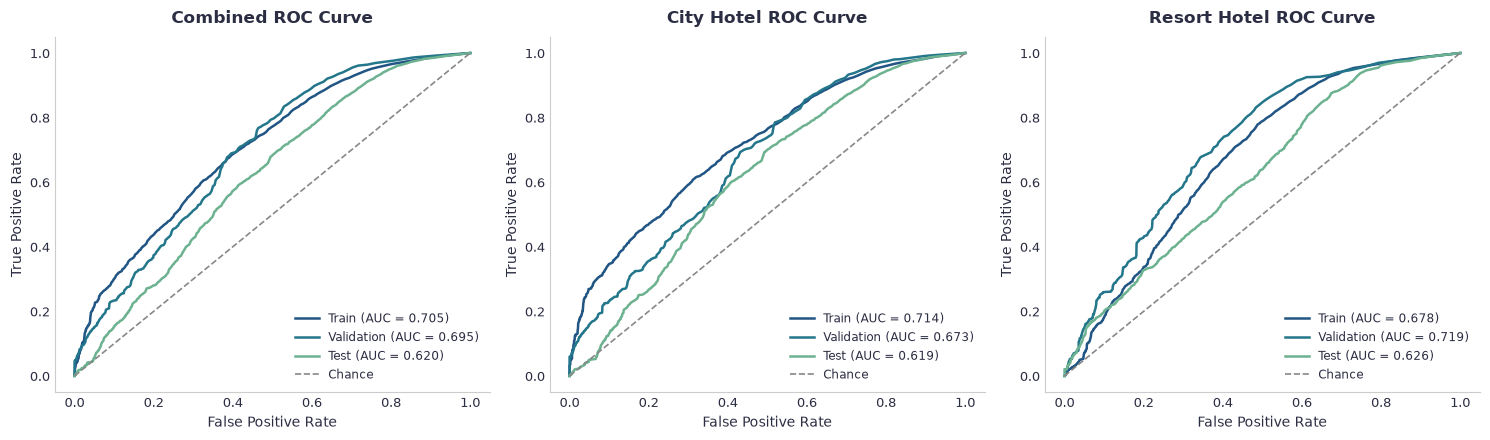

In [17]:
# Evaluate Models Across Partitions & Visualize ROC Curves
p_logit_train = logit_model.predict_proba(X_train[["lead_time"]])[:, 1]
p_logit_val = logit_model.predict_proba(X_val[["lead_time"]])[:, 1]
p_logit_test = logit_model.predict_proba(X_test[["lead_time"]])[:, 1]

splits_data = [
    ("Train", y_train.values, p_logit_train, hotel_train),
    ("Validation", y_val.values, p_logit_val, hotel_val),
    ("Test", y_test.values, p_logit_test, hotel_test),
]

metrics_records = []
for sname, y_true, p_pred, h_arr in splits_data:
    p_train_base = np.full_like(y_true, p_train_const, dtype=float)
    p_test_base = np.full_like(y_true, p_test_const, dtype=float)
    subsets = [
        ("Combined", np.ones(len(y_true), dtype=bool)),
        ("City Hotel", h_arr == "City Hotel"),
        ("Resort Hotel", h_arr == "Resort Hotel"),
    ]
    for hname, mask in subsets:
        yt = y_true[mask]
        pp = p_pred[mask]
        pc_tr = p_train_base[mask]
        pc_te = p_test_base[mask]

        # Univariate Logistic Regression
        roc_logit = roc_auc_score(yt, pp)
        pr_logit = average_precision_score(yt, pp)
        ll_logit = log_loss(yt, pp)
        br_logit = brier_score_loss(yt, pp)

        # Constant Baselines
        pr_base = average_precision_score(yt, pc_tr)
        ll_train_base = log_loss(yt, pc_tr)
        br_train_base = brier_score_loss(yt, pc_tr)

        ll_test_base = log_loss(yt, pc_te)
        br_test_base = brier_score_loss(yt, pc_te)

        metrics_records.append({
            "Split": sname,
            "Hotel": hname,
            "N": len(yt), 
            "Cancel %": f"{yt.mean():.1%}",
            "Logit ROC": f"{roc_logit:.4f}",
            "Logit PR": f"{pr_logit:.4f}",
            "Base PR": f"{pr_base:.4f}",
            "Logit Loss": f"{ll_logit:.4f}",
            "Train Base Loss": f"{ll_train_base:.4f}",
            "Test Base Loss": f"{ll_test_base:.4f}",
            "Logit Brier": f"{br_logit:.4f}",
            "Train Base Brier": f"{br_train_base:.4f}",
            "Test Base Brier": f"{br_test_base:.4f}",
        })

metrics_df = pd.DataFrame(metrics_records)
print("=== Model Performance Comparison ===")
print(metrics_df.to_string(index=False))

# Visualize ROC Curves for Univariate Logistic Regression
pal = sns.color_palette("crest", 4)
colors = {"Train": pal[3], "Validation": pal[2], "Test": pal[0]}

fig, axes = create_figure(nrows=1, ncols=3, figsize=(15, 4.5), grid="none")

subsets_cfg = [
    ("Combined ROC Curve", lambda h: np.ones(len(h), dtype=bool)),
    ("City Hotel ROC Curve", lambda h: h == "City Hotel"),
    ("Resort Hotel ROC Curve", lambda h: h == "Resort Hotel"),
]

for ax, (title, filter_fn) in zip(axes, subsets_cfg):
    for sname, yt, pp, h_arr in [
        ("Train", y_train.values, p_logit_train, hotel_train),
        ("Validation", y_val.values, p_logit_val, hotel_val),
        ("Test", y_test.values, p_logit_test, hotel_test),
    ]:
        m = filter_fn(h_arr)
        fpr, tpr, _ = roc_curve(yt[m], pp[m])
        auc = roc_auc_score(yt[m], pp[m])
        ax.plot(
            fpr,
            tpr,
            label=f"{sname} (AUC = {auc:.3f})",
            color=colors[sname],
            linewidth=1.8,
        )

    ax.plot([0, 1], [0, 1], linestyle="--", color="#888888", linewidth=1.2, label="Chance")
    ax.set_title(title)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right", fontsize=8.5)
    apply_grid(ax, grid="none")

plt.tight_layout()
plt.show()


### Key Observations & Considerations for Subsequent Models

- **Generalization Gap Across Time:** While the univariate model achieves stable performance on train and validation (ROC-AUC $\approx 0.70$, PR-AUC $\approx 0.55$), discriminative ability drops sharply on the test set (ROC-AUC $= 0.6197$).
- **Probability Calibration and Baseline Benchmarks:** On the test set, the constant training baseline achieves a log loss of $0.6792$ and Brier score of $0.2430$. An empirical test-mean baseline ($\bar{y}_{\text{test}} = 40.55\%$) sets an uncalibrated loss floor of $0.6752$ (Brier $0.2411$). The univariate logit model ($0.6793$ / $0.2415$) fails to beat even the naive constant training baseline in log loss, and falls short of the test-marginal baseline due to probability miscalibration driven by the summer cancellation surge.
- **Vulnerability to Seasonal Shocks:** The test partition spans the peak summer season (May–August 2017), during which Resort Hotel cancellations surge from $24.6\%$ to $36.2\%$. A single static lead-time parameter cannot capture seasonal swings or property-specific demand shifts.
- **Requirement for Multivariate Signals:** Subsequent models must incorporate calendar/timing features (`arrival_date_month`, `arrival_date_week_number`), customer segments, pricing (`adr`), and past cancellation records to capture orthogonal variance.
- **Capturing Cross-Property Interactions:** City and resort properties display divergent seasonal demand; future architectures will need to model interaction terms (`hotel` $\times$ `lead_time`, `hotel` $\times$ `month`).
- **Non-Linear Model Exploration:** Tree-based ensemble methods (e.g., gradient boosted decision trees) should be benchmarked to assess whether non-linear splits and feature interactions bridge the test degradation.
